# 03 · Train dense capacity controls

Train two three-layer dense MLPs, approximately matching the learned MoE active and total parameter counts.

**Run cells in order.** The default smoke preset validates the pipeline; it is too small for a scientific conclusion.

## Setup

In [1]:
from pathlib import Path
import os, sys
ROOT = Path.cwd().resolve()
if not (ROOT / 'src' / 'twilight_moe').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'twilight_moe').exists(), 'Start Jupyter from the project folder'
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from twilight_moe.config import load_config, run_dir
from twilight_moe.plotting import style, save_figure, COLORS
cfg = load_config()
style()
print('Preset:', cfg['name'], '| seeds:', cfg['seeds'])
print('Dataset root:', cfg['data_root'])

Preset: experiment | seeds: [7, 17, 27]
Dataset root: E:/HarunoKen/Twilight_MoE_Dynamics


## Inspect models

Hidden widths and capacity counts are explicit. Active parameters are a proxy, not a FLOP measurement.

In [2]:
from twilight_moe.models import build_model
names = ['dense_active', 'dense_total']
display(pd.DataFrame([{'model': name, **build_model(name, cfg).capacity()} for name in names]))
print(build_model(names[0], cfg))

,model,total_parameters,trainable_parameters,active_parameters
0,dense_active,5419,5419,5419
1,dense_total,7564,7564,7564


Dense(
  (network): Sequential(
    (0): Linear(in_features=32, out_features=57, bias=True)
    (1): Tanh()
    (2): Linear(in_features=57, out_features=57, bias=True)
    (3): Tanh()
    (4): Linear(in_features=57, out_features=4, bias=True)
  )
)


## Train and select checkpoints

The selected epoch minimizes validation MSE. Test evaluation occurs after selection. Losses for training are normalized; reported test MSE is in original state units.

In [3]:
from twilight_moe.experiment import run_models
rows = run_models(cfg, names)
display(rows[['model', 'seed', 'best_epoch', 'test_mse', 'training_seconds']].round(6))

dense_active  seed=7 test MSE=0.011182; best epoch=39


dense_total   seed=7 test MSE=0.011116; best epoch=37


dense_active  seed=17 test MSE=0.011312; best epoch=38


dense_total   seed=17 test MSE=0.011202; best epoch=38


dense_active  seed=27 test MSE=0.010898; best epoch=39


dense_total   seed=27 test MSE=0.010884; best epoch=38


,model,seed,best_epoch,test_mse,training_seconds
0,dense_active,7,39,0.011182,13.759586
1,dense_total,7,37,0.011116,13.892937
2,dense_active,17,38,0.011312,13.910919
3,dense_total,17,38,0.011202,14.561110
4,dense_active,27,39,0.010898,14.091276
5,dense_total,27,38,0.010884,14.372336


## Plot validation learning curves

The first seed is shown. Each model has a separate history CSV for every seed.

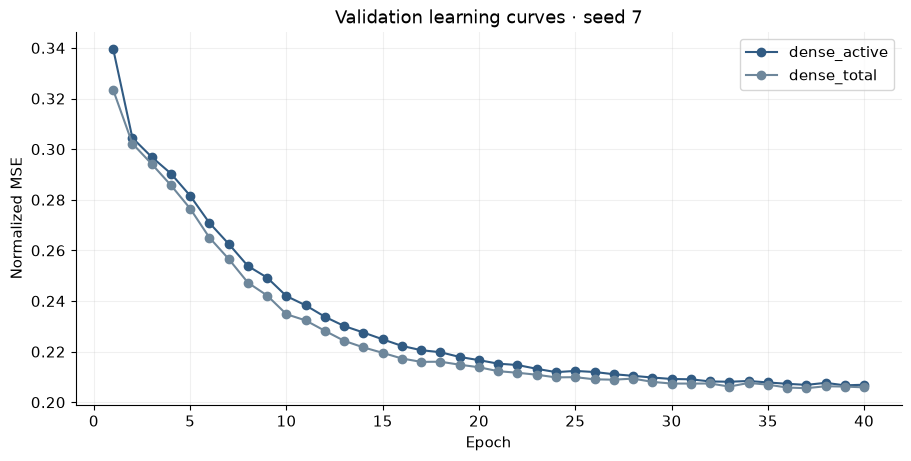

In [4]:
seed = cfg['seeds'][0]
fig, ax = plt.subplots()
for name in names:
    history = pd.read_csv(run_dir(cfg) / f'{name}_seed{seed}_history.csv')
    ax.plot(history['epoch'], history['val_mse_normalized'], marker='o',
            label=name, color=COLORS[name])
ax.set(title=f'Validation learning curves · seed {seed}', xlabel='Epoch', ylabel='Normalized MSE')
ax.legend()
save_figure(fig, cfg, 'learning_' + names[0])
plt.show()

## Interpretation

The random router is frozen and input-dependent. The oracle sees true regimes and activates one expert. A best checkpoint at the last epoch is a reason to examine training length, not proof of convergence. Do not tune repeatedly against these test errors.